In [3]:
import torch
from torch import nn
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch:", torch.__version__)
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.1+cu130
device: cuda
GPU: NVIDIA GeForce RTX 2050


In [4]:
tf = transforms.Compose([
    transforms.Lambda(lambda img: TF.hflip(TF.rotate(img, -90))),  # sửa hướng ảnh EMNIST
    transforms.ToTensor(),
    transforms.Normalize((0.1736,), (0.3317,)),
])

train_full = datasets.EMNIST("../data", split="balanced", train=True,  download=True, transform=tf)
test_set   = datasets.EMNIST("../data", split="balanced", train=False, download=True, transform=tf)

print("train:", len(train_full), "| test:", len(test_set))
img, label = train_full[0]
print("shape:", img.shape, "| label:", label)

100.0%


train: 112800 | test: 18800
shape: torch.Size([1, 28, 28]) | label: 45


In [6]:
classes = list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt")
print(len(classes))        # phải ra 47
print(classes[label])      # ký tự của ảnh đầu tiên

47
r


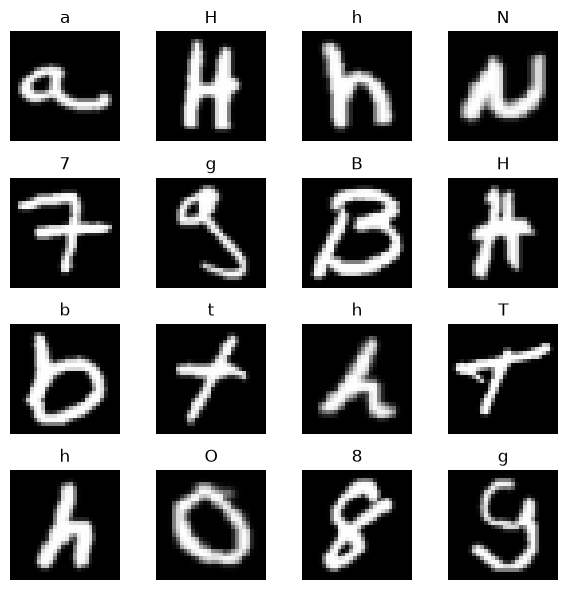

In [7]:
import random

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax in axes.flat:
    i = random.randrange(len(train_full))
    img, lab = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[lab])
    ax.axis("off")
plt.tight_layout()
plt.show()

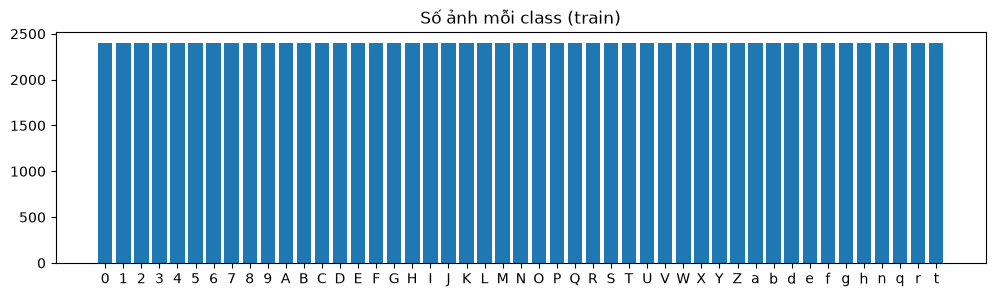

In [8]:
from collections import Counter

counts = Counter(train_full.targets.tolist())
plt.figure(figsize=(12, 3))
plt.bar([classes[k] for k in sorted(counts)], [counts[k] for k in sorted(counts)])
plt.title("Số ảnh mỗi class (train)")
plt.show()

In [10]:
from torch.utils.data import random_split, DataLoader

g = torch.Generator().manual_seed(42)
train_set, val_set = random_split(train_full, [0.9, 0.1], generator=g)

print("train:", len(train_set))
print("val:  ", len(val_set))
print("test: ", len(test_set))

train: 101520
val:   11280
test:  18800


In [11]:
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          pin_memory=(device == "cuda"))
val_loader   = DataLoader(val_set,   batch_size=256, shuffle=False,
                          pin_memory=(device == "cuda"))
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False,
                          pin_memory=(device == "cuda"))

print("so batch:", len(train_loader), len(val_loader), len(test_loader))

so batch: 794 45 74


In [12]:
xb, yb = next(iter(train_loader))
print("xb:", xb.shape, xb.dtype)
print("yb:", yb.shape, yb.dtype)
print("mean:", xb.mean().item(), "| std:", xb.std().item())
print("min/max:", xb.min().item(), xb.max().item())

xb: torch.Size([128, 1, 28, 28]) torch.float32
yb: torch.Size([128]) torch.int64
mean: -0.0027601488400250673 | std: 1.004988670349121
min/max: -0.5233644843101501 2.491407871246338


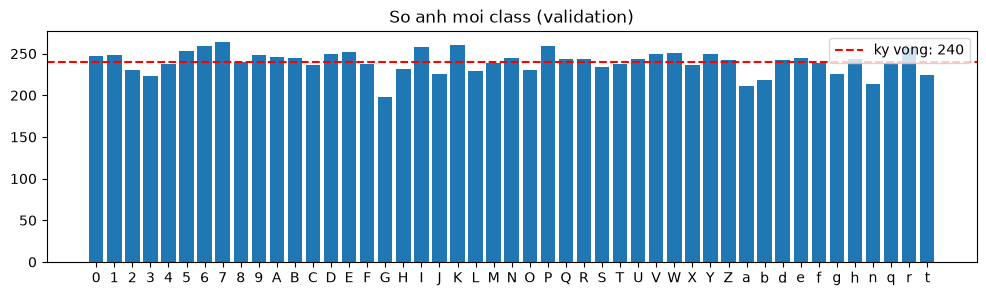

min: 198 | max: 264


In [13]:
from collections import Counter

val_labels = [train_full.targets[i].item() for i in val_set.indices]
vc = Counter(val_labels)

plt.figure(figsize=(12, 3))
plt.bar([classes[k] for k in sorted(vc)], [vc[k] for k in sorted(vc)])
plt.axhline(240, color="red", linestyle="--", label="ky vong: 240")
plt.legend(); plt.title("So anh moi class (validation)")
plt.show()

print("min:", min(vc.values()), "| max:", max(vc.values()))

In [14]:
mlp = nn.Sequential(
    nn.Flatten(),                 # (B,1,28,28) -> (B,784)
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 47),           # 47 logits
).to(device)

In [15]:
class GlyphCNN(nn.Module):
    def __init__(self, n_classes=47):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn = GlyphCNN().to(device)

In [16]:
x = next(iter(train_loader))[0][:1].to(device)    # lay 1 anh
print("input", tuple(x.shape))

with torch.no_grad():
    for layer in cnn.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:10s}", tuple(x.shape))
    for layer in cnn.classifier:
        x = layer(x)
        print(f"{layer.__class__.__name__:10s}", tuple(x.shape))

input (1, 1, 28, 28)
Conv2d     (1, 32, 28, 28)
ReLU       (1, 32, 28, 28)
MaxPool2d  (1, 32, 14, 14)
Conv2d     (1, 64, 14, 14)
ReLU       (1, 64, 14, 14)
MaxPool2d  (1, 64, 7, 7)
Flatten    (1, 3136)
Linear     (1, 128)
ReLU       (1, 128)
Dropout    (1, 128)
Linear     (1, 47)


In [17]:
import math

def count_params(m):
    return sum(p.numel() for p in m.parameters())

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)
criterion = nn.CrossEntropyLoss()

for name, m in [("MLP", mlp), ("CNN", cnn)]:
    m.eval()
    with torch.no_grad():
        out = m(xb)
        loss = criterion(out, yb).item()
        acc = (out.argmax(1) == yb).float().mean().item()
    print(f"{name}: out {tuple(out.shape)} | params {count_params(m):,} | loss {loss:.3f} | acc {acc:.3f}")

print("ln(47) =", round(math.log(47), 3))


MLP: out (128, 47) | params 213,039 | loss 3.877 | acc 0.016
CNN: out (128, 47) | params 426,415 | loss 3.859 | acc 0.023
ln(47) = 3.85


In [18]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)                 # 1. forward
            loss = criterion(logits, y)       # 2. tinh loss

            if train:
                optimizer.zero_grad()         # 5. xoa gradient cu
                loss.backward()               # 3. backward
                optimizer.step()              # 4. cap nhat weight

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)

    return total_loss / n, correct / n

In [19]:
import time

def fit(model, name, epochs=10, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val = 0.0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)

        for k, v in zip(history, [tl, ta, vl, va]):
            history[k].append(v)

        if va > best_val:                       # luu model tot nhat theo val acc
            best_val = va
            torch.save(model.state_dict(), f"../models/{name}_best.pt")

        print(f"[{name}] epoch {epoch:2d} | "
              f"train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s")
    return history

In [20]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256), nn.ReLU(),
        nn.Linear(256, 47),
    ).to(device)

torch.manual_seed(42)
mlp = make_mlp()
hist_mlp = fit(mlp, "mlp", epochs=10)

torch.manual_seed(42)
cnn = GlyphCNN().to(device)
hist_cnn = fit(cnn, "cnn", epochs=10)

[mlp] epoch  1 | train loss 1.016 acc 0.703 | val loss 0.706 acc 0.787 | 25.9s
[mlp] epoch  2 | train loss 0.600 acc 0.808 | val loss 0.587 acc 0.816 | 23.9s
[mlp] epoch  3 | train loss 0.504 acc 0.833 | val loss 0.549 acc 0.825 | 25.5s
[mlp] epoch  4 | train loss 0.455 acc 0.847 | val loss 0.524 acc 0.831 | 25.8s
[mlp] epoch  5 | train loss 0.419 acc 0.856 | val loss 0.513 acc 0.840 | 28.6s
[mlp] epoch  6 | train loss 0.392 acc 0.863 | val loss 0.520 acc 0.834 | 27.4s
[mlp] epoch  7 | train loss 0.370 acc 0.868 | val loss 0.512 acc 0.836 | 28.1s
[mlp] epoch  8 | train loss 0.347 acc 0.875 | val loss 0.525 acc 0.835 | 27.6s
[mlp] epoch  9 | train loss 0.333 acc 0.879 | val loss 0.533 acc 0.836 | 27.4s
[mlp] epoch 10 | train loss 0.319 acc 0.883 | val loss 0.554 acc 0.833 | 27.5s
[cnn] epoch  1 | train loss 0.961 acc 0.707 | val loss 0.472 acc 0.838 | 34.2s
[cnn] epoch  2 | train loss 0.544 acc 0.818 | val loss 0.406 acc 0.856 | 34.9s
[cnn] epoch  3 | train loss 0.470 acc 0.839 | val lo

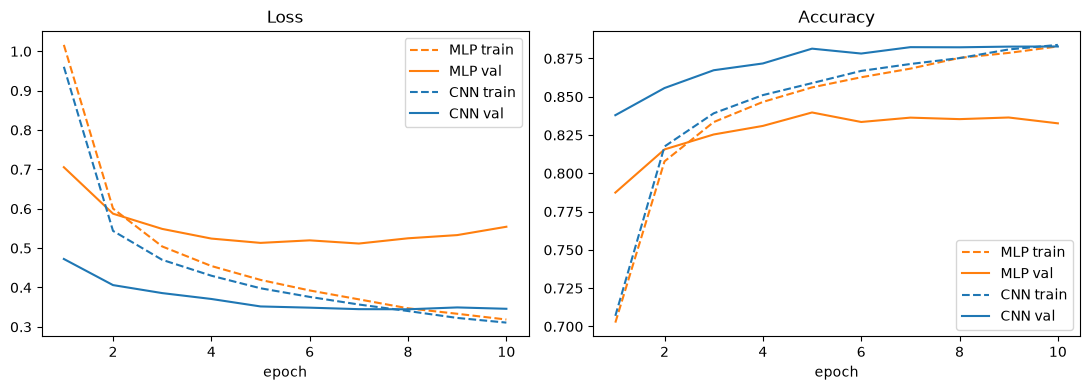

Best val acc | MLP: 0.8397163120567376 | CNN: 0.8828014184397163


In [21]:
epochs_axis = range(1, len(hist_cnn["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, h, color in [("MLP", hist_mlp, "tab:orange"), ("CNN", hist_cnn, "tab:blue")]:
    ax[0].plot(epochs_axis, h["train_loss"], color=color, linestyle="--", label=f"{name} train")
    ax[0].plot(epochs_axis, h["val_loss"],   color=color,                 label=f"{name} val")
    ax[1].plot(epochs_axis, h["train_acc"],  color=color, linestyle="--", label=f"{name} train")
    ax[1].plot(epochs_axis, h["val_acc"],    color=color,                 label=f"{name} val")

ax[0].set_title("Loss");     ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Best val acc | MLP:", max(hist_mlp["val_acc"]), "| CNN:", max(hist_cnn["val_acc"]))

In [22]:
mlp_best = make_mlp()
mlp_best.load_state_dict(torch.load("../models/mlp_best.pt", map_location=device))

cnn_best = GlyphCNN().to(device)
cnn_best.load_state_dict(torch.load("../models/cnn_best.pt", map_location=device))

<All keys matched successfully>

In [23]:
import numpy as np

@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps, cs = [], [], []
    for x, y in loader:
        probs = torch.softmax(model(x.to(device)), dim=1)
        conf, pred = probs.max(dim=1)
        ys.append(y); ps.append(pred.cpu()); cs.append(conf.cpu())
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(cs).numpy()

In [24]:
from scipy.stats import chi2

def acc_ci(y_true, y_pred, z=1.96):
    n = len(y_true)
    p = (y_true == y_pred).mean()
    se = np.sqrt(p * (1 - p) / n)
    return p, p - z * se, p + z * se

yv, pv_mlp, cv_mlp = predict_all(mlp_best, val_loader)
_,  pv_cnn, cv_cnn = predict_all(cnn_best, val_loader)

for name, pred in [("MLP", pv_mlp), ("CNN", pv_cnn)]:
    p, lo, hi = acc_ci(yv, pred)
    print(f"{name}: accuracy {p:.4f} | 95% CI [{lo:.4f}, {hi:.4f}]")

ok_mlp, ok_cnn = (pv_mlp == yv), (pv_cnn == yv)
b = (ok_mlp & ~ok_cnn).sum()     # MLP dung, CNN sai
c = (~ok_mlp & ok_cnn).sum()     # MLP sai, CNN dung
stat = (abs(b - c) - 1) ** 2 / (b + c)
print(f"b={b}, c={c}, chi2={stat:.1f}, p-value={chi2.sf(stat, 1):.2e}")

MLP: accuracy 0.8397 | 95% CI [0.8329, 0.8465]
CNN: accuracy 0.8828 | 95% CI [0.8769, 0.8887]
b=360, c=846, chi2=195.0, p-value=2.52e-44


In [25]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(yv, pv_cnn, target_names=classes, digits=3))

              precision    recall  f1-score   support

           0      0.637     0.725     0.678       247
           1      0.551     0.802     0.654       248
           2      0.854     0.917     0.885       230
           3      0.978     0.978     0.978       223
           4      0.944     0.924     0.934       237
           5      0.929     0.885     0.907       253
           6      0.936     0.900     0.917       259
           7      0.988     0.973     0.981       264
           8      0.906     0.963     0.933       240
           9      0.696     0.879     0.777       248
           A      0.946     0.988     0.966       246
           B      0.967     0.955     0.961       245
           C      0.969     0.941     0.955       236
           D      0.916     0.916     0.916       250
           E      0.983     0.937     0.959       252
           F      0.659     0.706     0.682       238
           G      0.880     0.924     0.901       198
           H      0.973    

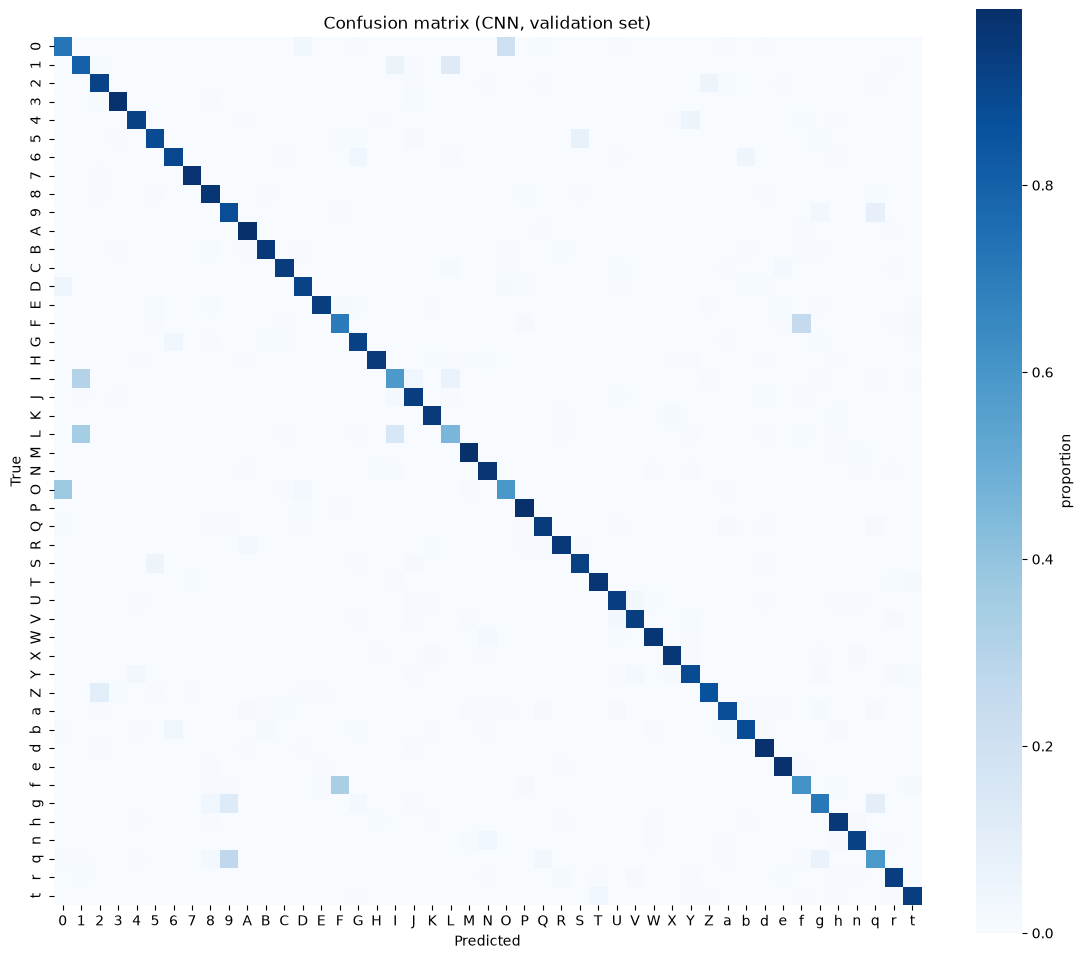

In [26]:
import seaborn as sns

cm = confusion_matrix(yv, pv_cnn, labels=range(47))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, xticklabels=classes, yticklabels=classes,
            cmap="Blues", square=True, cbar_kws={"label": "proportion"})
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix (CNN, validation set)")
plt.show()

In [27]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = [(cm_off[t, p], classes[t], classes[p])
         for t in range(47) for p in range(47) if cm_off[t, p] > 0]

for n, t, p in sorted(pairs, reverse=True)[:10]:
    print(f"true '{t}' predicted as '{p}': {n} images")

true 'O' predicted as '0': 86 images
true 'f' predicted as 'F': 80 images
true 'L' predicted as '1': 80 images
true 'I' predicted as '1': 78 images
true 'q' predicted as '9': 64 images
true 'F' predicted as 'f': 60 images
true '0' predicted as 'O': 52 images
true 'L' predicted as 'I': 36 images
true '1' predicted as 'L': 31 images
true 'g' predicted as '9': 29 images


wrong: 1322 / 11280


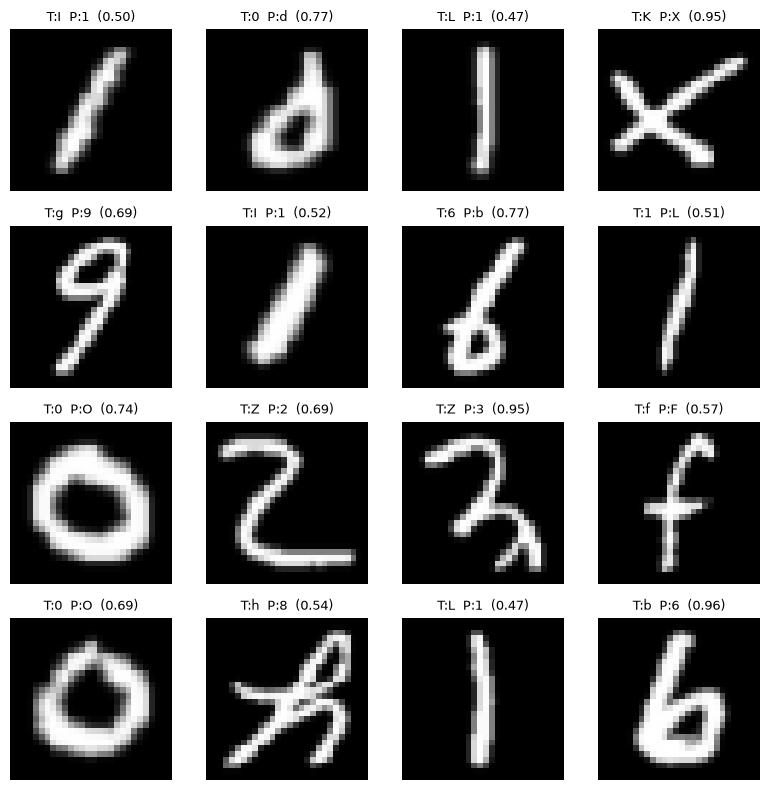

In [28]:
wrong = np.where(pv_cnn != yv)[0]
print(f"wrong: {len(wrong)} / {len(yv)}")

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for ax, i in zip(axes.flat, np.random.choice(wrong, 16, replace=False)):
    img, _ = val_set[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"T:{classes[yv[i]]}  P:{classes[pv_cnn[i]]}  ({cv_cnn[i]:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

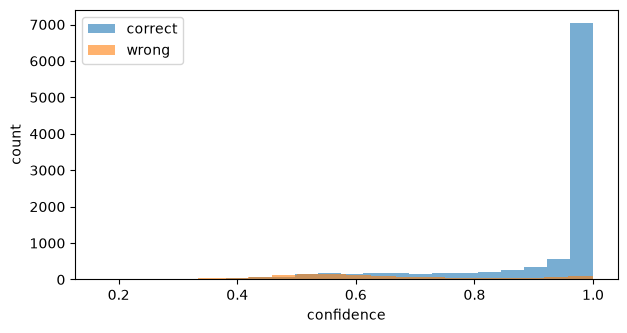

In [29]:
plt.figure(figsize=(7, 3.5))
plt.hist(cv_cnn[pv_cnn == yv], bins=20, alpha=0.6, label="correct")
plt.hist(cv_cnn[pv_cnn != yv], bins=20, alpha=0.6, label="wrong")
plt.xlabel("confidence"); plt.ylabel("count"); plt.legend()
plt.show()